## Exploratory data analysis

Before building models, we look at the data to understand who is poor, how consumption is spread, how many transfers each village gets, and which features differ between neighbours.

We only use the **training villages** and the test villages stay untouched until the very end, so that nothing we see here can influence our choices.

In [1]:
import os
import sys
sys.path.append("..")   # so the notebook finds the shared code in src/ which is one folder up

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import load_data 

train, test = load_data()  # clean data, so the training villages with fold and the test villages

os.makedirs("../outputs/figures", exist_ok=True)
print("train:", train.shape, "| villages:", train["hhea"].nunique()) 

train: (4090, 113) | villages: 512


In [2]:
# Share of poor households overall, by province and urban/rural area. 
# Each group is measured against its own poverty line, so these shares compare relative poverty.

poor = train["poor"].astype(float)   # 1 = poor, 0 = not poor
print(f"Share poor (all training households): {poor.mean():.1%}")

# share of poor households and number of households per province
# prop codes (official BPS codes): 12 = North Sumatra, 33 = Central Java, 73 = South Sulawesi
display(train.groupby("prop")["poor"].agg(["mean", "count"]))

# share of poor households and number of households per urban/rural area (urban = 1, rural = 0)
display(train.groupby("urban")["poor"].agg(["mean", "count"]))

Share poor (all training households): 36.3%


,mean,count
prop,,
12,0.323699,1038
33,0.42663,1840
73,0.29868,1212


,mean,count
urban,,
0,0.407283,2087
1,0.316026,2003


Central Java is the largest province (33) and it has the most poverty.
Rural villages (41%) are poorer than urban ones (32%).


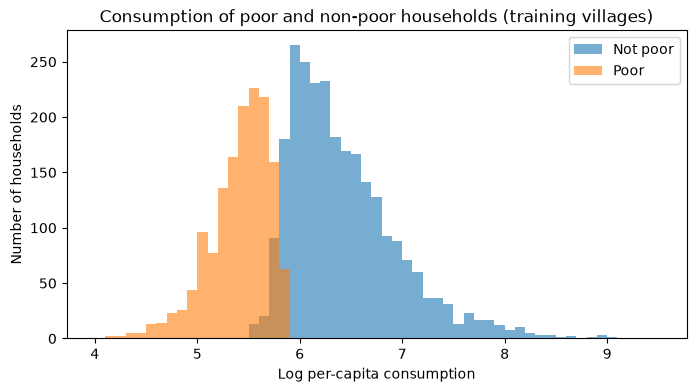

In [3]:
# Distribution of consumption, histogram of log consumption by poor vs non-poor
bins = np.linspace(4, 9.5, 56)

plt.figure(figsize=(8, 4))
plt.hist(train.loc[train["poor"] == 0, "LOGCONSUMPTION"], bins=bins, alpha=0.6, label="Not poor")
plt.hist(train.loc[train["poor"] == 1, "LOGCONSUMPTION"], bins=bins, alpha=0.6, label="Poor")
plt.xlabel("Log per-capita consumption")
plt.ylabel("Number of households")
plt.title("Consumption of poor and non-poor households (training villages)")
plt.legend()
plt.savefig("../outputs/figures/eda_consumption.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

There is a small overlap zone, which we can see by the overlap of the two colors. It comes from the poverty line because the same level of consumption can lead in one region to being poor and in another region to be not poor. 

In [4]:
# Transfers quotas per village, it is `round(village size x share)`

villages = train.groupby("hhea").agg(n_households=("hhid", "size"),
                                     share=("share", "first"),     # same value for the whole village
                                     n_poor=("poor", "sum"))
villages["n_slots"] = (villages["n_households"] * villages["share"]).round()
# village size, not 8, because seven of the villages only have 7 households

print("Number of transfers per village:")
print(villages["n_slots"].value_counts().sort_index())

print(f"Villages with more poor households than transfers: {(villages['n_poor'] > villages['n_slots']).mean():.1%}")
print(f"Total: {int(villages['n_slots'].sum())} transfers for {int(villages['n_poor'].sum())} poor households")

Number of transfers per village:
n_slots
0.0     15
1.0    116
2.0    151
3.0     98
4.0     73
5.0     38
6.0     17
7.0      4
Name: count, dtype: int64
Villages with more poor households than transfers: 46.7%
Total: 1324 transfers for 1483 poor households


In [5]:
# What varies within a village
# Households are ranked inside each village, so a feature that is the same for every household in a village cannot change who gets the transfer. 
# For each feature we measure the **share of its variation that is within villages** (identical = 0%, almost all differences are between neigbours = close to 100%).

features = ["hhsize", "depratio", "tfloor", "twall", "troof", "toilet", "water",
            "lighting", "fcook", "house", "urban", "prop"]

rows = []
for f in features:
    x = train[f].astype(float)   
    within = x - x.groupby(train["hhea"]).transform("mean")     # because the distance of each household from its own village average = the part that differs between neighbours
    rows.append({"feature": f, "share_within": within.var() / x.var()})     # share_within = variation between neighbours / total variation

variation = pd.DataFrame(rows).sort_values("share_within")
display(variation.round(2))

,feature,share_within
10,urban,0.00
11,prop,0.00
4,troof,0.16
6,water,0.50
8,fcook,0.52
2,tfloor,0.60
3,twall,0.62
9,house,0.66
5,toilet,0.67
7,lighting,0.71


**Result:**

- **36% of training households are poor.** Poverty is highest in Central Java (43%) and in rural villages (41% vs. 32% in urban ones).
- **Poor households have lower consumption**, with a small overlap because the poverty line differs by province and urban/rural area.
- **Transfers are scarce**: most villages get 1 to 3 transfers for 8 households, and 15 villages get none. In 47% of the villages there are more poor households than transfers (1,324 transfers for 1,483 poor households in total). This is why even a perfect ranking cannot reach every poor household.
- **Some features are the same for all neighbours**: `urban` and the province do not vary within a village at all, and roof type (`troof`) varies mostly between villages (16% within). Household size and the dependency ratio vary mostly between neighbours (80% or more within).
- This supports the feedback: village-level features cannot change who is chosen inside a village, so the linear models leave them out.
